# CatBoost on the Titanic — Survival Prediction


All scores are **computed by running the models** — nothing is hard-coded.

### Theory recap
* **Gradient boosting** builds shallow trees *sequentially*; each tree fits the errors (negative gradient of the loss) of the ensemble so far:
$$F_m(x)=F_{m-1}(x)+\eta\,h_m(x),\qquad h_m \approx -\frac{\partial L(y,F_{m-1}(x))}{\partial F_{m-1}(x)}$$
* Binary classification minimises **Logloss** with $p=\sigma(F(x))=\frac{1}{1+e^{-F(x)}}$:
$$L=-\frac1n\sum_i\big[y_i\log p_i+(1-y_i)\log(1-p_i)\big]$$
* **What makes CatBoost different:** *ordered boosting* (reduces prediction shift), *ordered target statistics* for categorical features, *symmetric trees* (regularise, predict fast), native missing-value handling.

## Dataset introduction
* **What it is:** passenger records from the **RMS Titanic**, which sank on 15 April 1912 after hitting an iceberg. The task is a **binary classification**: predict whether a passenger survived.
* **Source:** Kaggle competition *Titanic: Machine Learning from Disaster* — https://www.kaggle.com/competitions/titanic
* **Number of samples:** `train.csv` has **891 labeled passengers**; `test.csv` has **418 passengers without labels** (used only for competition-style predictions); `gender_submission.csv` is Kaggle's example submission format.
* **Target variable:** `Survived` (0 = died, 1 = survived); about **38.4%** of training passengers survived.
* **Features (11 + target):**

| Feature | Type | Meaning |
|---|---|---|
| `PassengerId` | identifier | Row id (not used for modelling) |
| `Pclass` | categorical | Ticket class: 1st, 2nd, 3rd (proxy for socio-economic status) |
| `Name` | text | Passenger name (we extract the title, e.g. Mr, Mrs, Miss) |
| `Sex` | categorical | male / female |
| `Age` | numeric | Age in years (some missing) |
| `SibSp` | numeric | Siblings / spouses aboard |
| `Parch` | numeric | Parents / children aboard |
| `Ticket` | text | Ticket number (dropped) |
| `Fare` | numeric | Ticket price in pounds |
| `Cabin` | text | Cabin number (mostly missing) |
| `Embarked` | categorical | Port: C = Cherbourg, Q = Queenstown, S = Southampton |

#### Cell 1 · Install
**What it does:** installs the libraries Colab lacks (CatBoost, SHAP, XGBoost, LightGBM, Optuna).

**What to say:** "Colab has pandas and scikit-learn already; these five are the extras."

In [1]:
!pip install -q catboost shap xgboost lightgbm optuna

#### Cell 2 · Imports and seed
**What it does:** imports data, plotting, scikit-learn, CatBoost and Optuna; sets `SEED = 42` and quietens Optuna's logs.

**What to say:** "One seed everywhere makes every split and model reproducible."

In [2]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import optuna
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from catboost import CatBoostClassifier, Pool
import catboost

SEED = 42
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", palette="deep")
print("CatBoost version:", catboost.__version__)

CatBoost version: 1.2.10


#### Cell 3 · Load and inspect
**What it does:** loads `train.csv` (891 labeled rows) and `test.csv` (418 unlabeled rows) — prompts for upload in Colab if missing — then prints shape, data types, sample rows and summary statistics.

**What to say:** "`test.csv` has no `Survived` column, so it can never be used for metrics; only for competition-style predictions at the end."

In [3]:
if not os.path.exists("train.csv"):
    try:
        from google.colab import files
        print("Please upload train.csv, test.csv and gender_submission.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Place train.csv and test.csv next to this notebook.")

df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
print("train:", df.shape, "| test:", test_df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:\n", df.dtypes)
display(df.head())
display(df.describe(include="all").T)

train: (891, 12) | test: (418, 11)

Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types:
 PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


#### Cell 4 · EDA dashboard
**What it does:** one 2×3 figure: survival counts, survival by Sex, by Pclass, Age and Fare distributions, and survival by embarkation port split by class.

**What to say:** "About 38% survived (moderate imbalance, so we stratify). Women and first class survived most — the 'women and children first' policy. Cherbourg looks safer mainly because it carried more first-class passengers: class is a confounder. Fare is right-skewed, but trees don't care about scale, so no log transform."

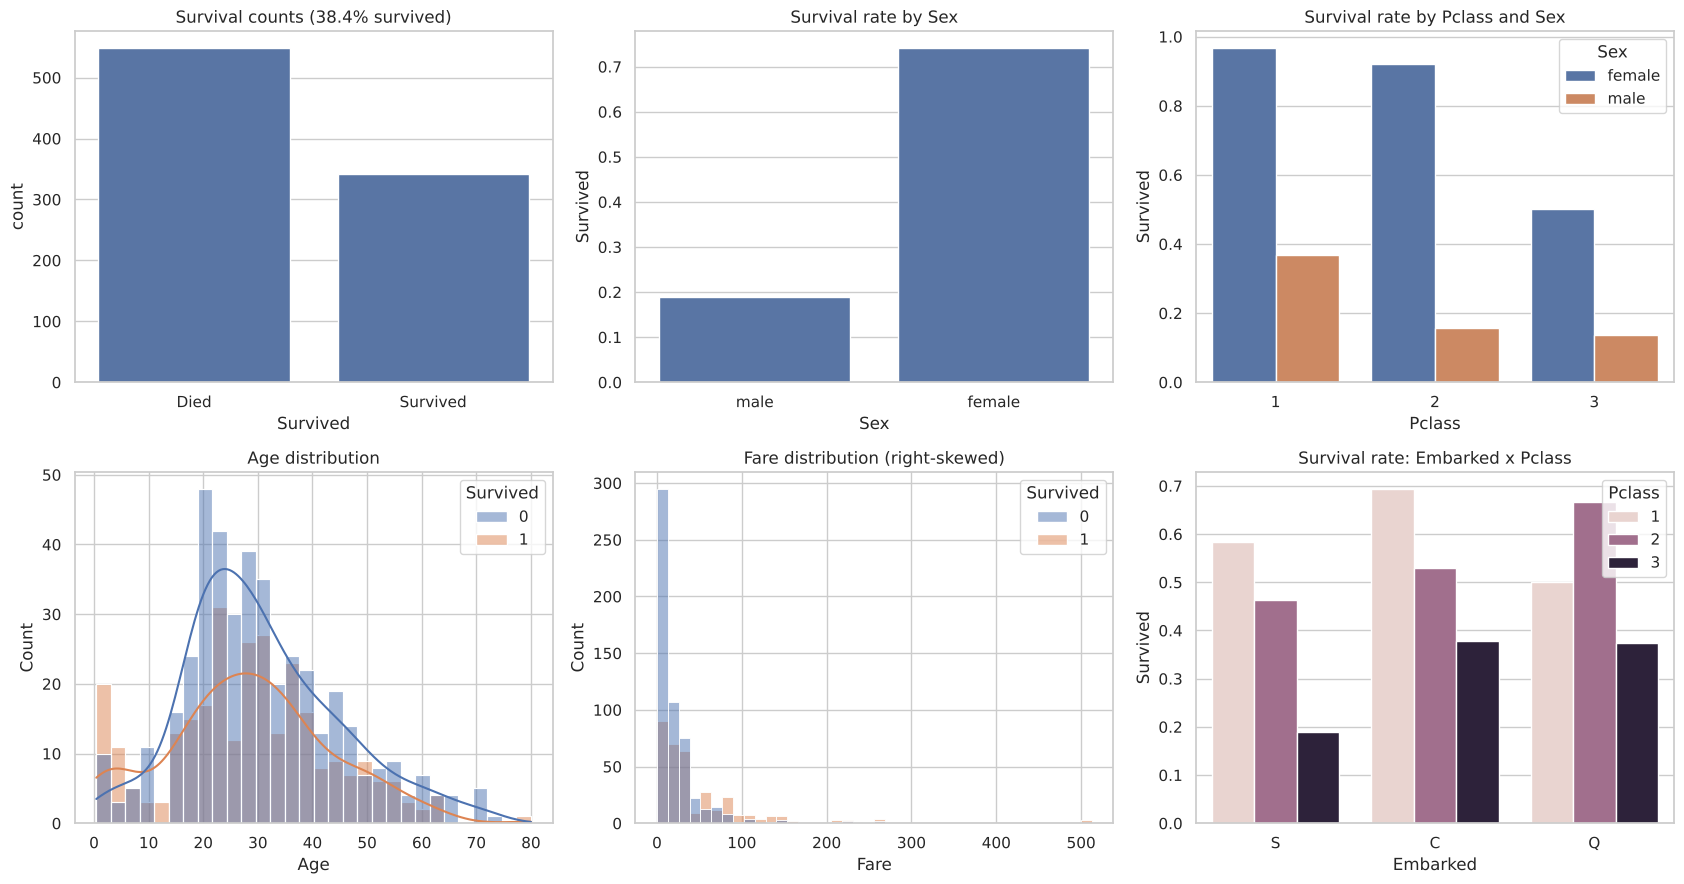

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
sns.countplot(x="Survived", data=df, ax=ax[0, 0]); ax[0, 0].set_xticklabels(["Died", "Survived"]); ax[0, 0].set_title(f"Survival counts ({df.Survived.mean():.1%} survived)")
sns.barplot(x="Sex", y="Survived", data=df, ax=ax[0, 1], errorbar=None); ax[0, 1].set_title("Survival rate by Sex")
sns.barplot(x="Pclass", y="Survived", hue="Sex", data=df, ax=ax[0, 2], errorbar=None); ax[0, 2].set_title("Survival rate by Pclass and Sex")
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=ax[1, 0]); ax[1, 0].set_title("Age distribution")
sns.histplot(data=df, x="Fare", hue="Survived", bins=40, ax=ax[1, 1]); ax[1, 1].set_title("Fare distribution (right-skewed)")
sns.barplot(x="Embarked", y="Survived", hue="Pclass", data=df, ax=ax[1, 2], errorbar=None); ax[1, 2].set_title("Survival rate: Embarked x Pclass")
plt.tight_layout(); plt.show()

#### Cell 5 · Missing values and correlation analysis
**What it does:** a table, bar chart and heatmap of missing values, plus a correlation heatmap of the numeric columns with `Survived`.

**What to say:** "Cabin is ~77 percent missing, Age ~20 percent, Embarked 2 rows. Cabin becomes a has-cabin flag plus a deck letter; Age stays missing for CatBoost (native handling) and is median-imputed inside the Random Forest pipeline. Correlation: Pclass (-0.34) and Fare (+0.26) have the strongest linear link to survival; Age (-0.08), SibSp (-0.04) and Parch (+0.08) are weak. Correlation only measures **linear** relationships between numeric columns, so it misses the strong Sex effect (a category) and interactions — which is why we use a tree model."

,missing,pct
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


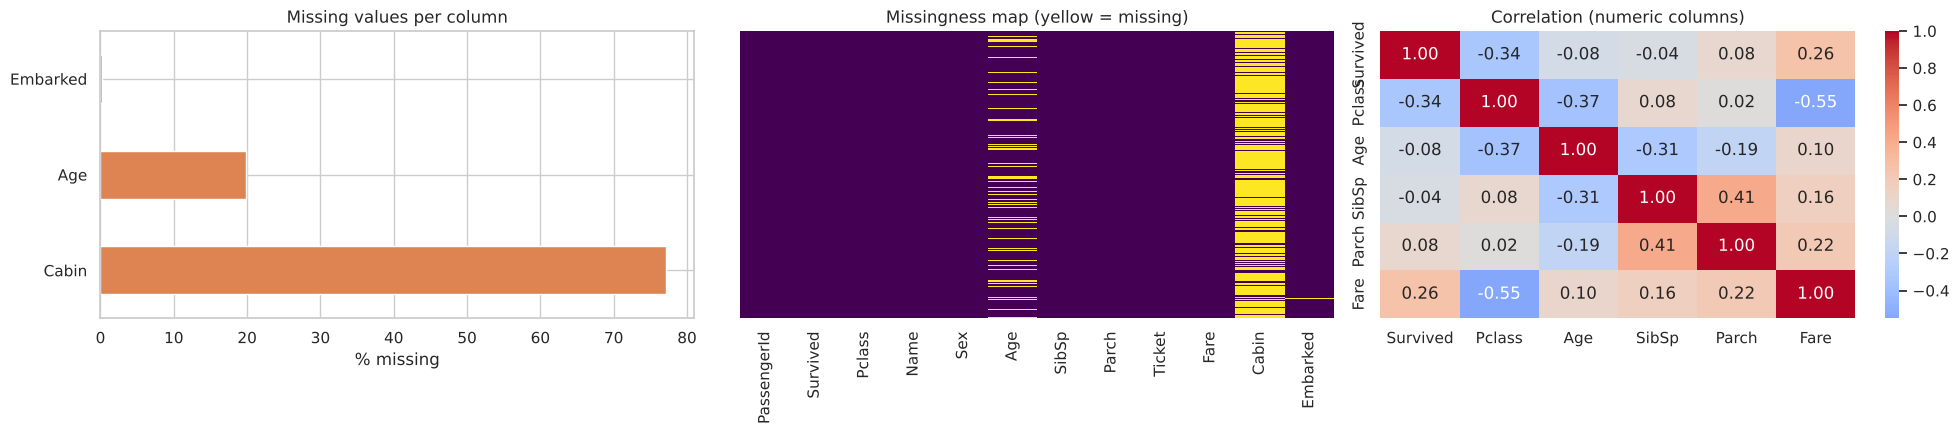

Correlation with Survived:
 Pclass   -0.34
Age      -0.08
SibSp    -0.04
Parch     0.08
Fare      0.26


In [5]:
missing = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean()*100).round(1)})
missing = missing[missing.missing > 0].sort_values("missing", ascending=False)
display(missing)
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
missing["pct"].plot.barh(ax=ax[0], color="#dd8452"); ax[0].set_xlabel("% missing"); ax[0].set_title("Missing values per column")
sns.heatmap(df.isna(), cbar=False, yticklabels=False, ax=ax[1], cmap="viridis"); ax[1].set_title("Missingness map (yellow = missing)")
num_corr = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr()
sns.heatmap(num_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[2]); ax[2].set_title("Correlation (numeric columns)")
plt.tight_layout(); plt.show()
print("Correlation with Survived:\n", num_corr["Survived"].drop("Survived").round(2).sort_values().to_string())

#### Cell 6 · Preprocessing: feature engineering and split
**What it does:** `add_features` works one row at a time, then a stratified **569 / 143 / 179** train / validation / test split (seed 42) is made.

| Step | What we did | Why it is needed for CatBoost (and the baseline) |
|---|---|---|
| Drop identifiers / unusable columns | Removed `PassengerId`, `Ticket`, raw `Name`, raw `Cabin` | An id carries no signal and can only be memorised; ticket and cabin strings are too sparse or high-cardinality |
| Missing values | `Age` kept as NaN for CatBoost; `Embarked` filled with "Missing"; Cabin turned into `HasCabin` + `Deck` | CatBoost handles NaN natively, so no information is invented. Random Forest cannot, so its pipeline median-imputes `Age` (fit on training data only) and adds a missing-indicator |
| Feature engineering | `Title` from `Name`; `FamilySize`, `IsAlone`; `HasCabin`, `Deck` | Trees cannot read raw text; these compact signals (social status, family context, cabin records) are far more useful than the raw strings |
| Encoding | Categorical columns (`Pclass, Sex, Embarked, Title, Deck`) passed as strings via `cat_features` | CatBoost encodes them internally with ordered target statistics, so no one-hot or label encoding is needed. Random Forest needs one-hot encoding in its pipeline |
| Scaling | **Not applied** | Tree-based models split on thresholds, so they are unaffected by feature scale. Scaling matters for distance- or gradient-based models (KNN, SVM, logistic regression), not here |
| Train / validation / test split | Stratified, seed 42 | Training teaches the model, validation drives early stopping, test is used once for an unbiased score. Stratification keeps the survival rate equal in all parts |

**Leakage rule:** every feature uses only that passenger's own row, and anything *learned* from data (imputation medians, encoders) is fit on training data only.

In [6]:
RARE_TITLES = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs", "Lady": "Rare", "Countess": "Rare", "Capt": "Rare", "Col": "Rare",
               "Don": "Rare", "Dr": "Rare", "Major": "Rare", "Rev": "Rare", "Sir": "Rare", "Jonkheer": "Rare", "Dona": "Rare"}

def add_features(data):
    # Row-wise feature engineering: uses no statistics from other rows, so it cannot leak.
    d = data.copy()
    d["Title"] = d["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip().replace(RARE_TITLES)
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
    d["HasCabin"] = d["Cabin"].notna().astype(int)
    d["Deck"] = d["Cabin"].str[0].fillna("Unknown")
    d["Embarked"] = d["Embarked"].fillna("Missing")
    d["Pclass"] = d["Pclass"].astype(str)
    return d

CAT_COLS = ["Pclass", "Sex", "Embarked", "Title", "Deck"]
NUM_COLS = ["Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "HasCabin"]
FEATURES = CAT_COLS + NUM_COLS

full = add_features(df)
X, y = full[FEATURES], full["Survived"]

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.20, stratify=y_trainval, random_state=SEED)
for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} n={len(part):>3}  survival rate={part.mean():.3f}")

train       n=569  survival rate=0.383
validation  n=143  survival rate=0.385
test        n=179  survival rate=0.385


#### Cell 7 · Train `CatBoostClassifier`
**What it does:** trains CatBoost with early stopping on the validation set, then plots training vs validation Logloss and validation AUC.

| Parameter | Meaning |
|---|---|
| `iterations` | Maximum number of trees |
| `learning_rate` ($\eta$) | Shrinks each tree's contribution; smaller needs more trees |
| `depth` | Depth of each symmetric tree ($2^d$ leaves) |
| `loss_function` | Objective optimised (`Logloss`) |
| `eval_metric` | Metric watched on validation data (`AUC`) |
| `l2_leaf_reg` | L2 penalty on leaf values (regulariser) |
| `random_seed` | Reproducibility |
| `early_stopping_rounds` | Stop when the eval metric hasn't improved for N rounds |

**What to say:** "We allow 1000 trees but it stops early once validation AUC stalls. The gap between the training and validation curves is where overfitting starts."

0:	test: 0.8026860	best: 0.8026860 (0)	total: 51ms	remaining: 51s


100:	test: 0.8530992	best: 0.8572314 (57)	total: 169ms	remaining: 1.51s


200:	test: 0.8556818	best: 0.8587810 (125)	total: 285ms	remaining: 1.13s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8587809917
bestIteration = 125

Shrink model to first 126 iterations.

Best iteration: 125 | trees kept: 126


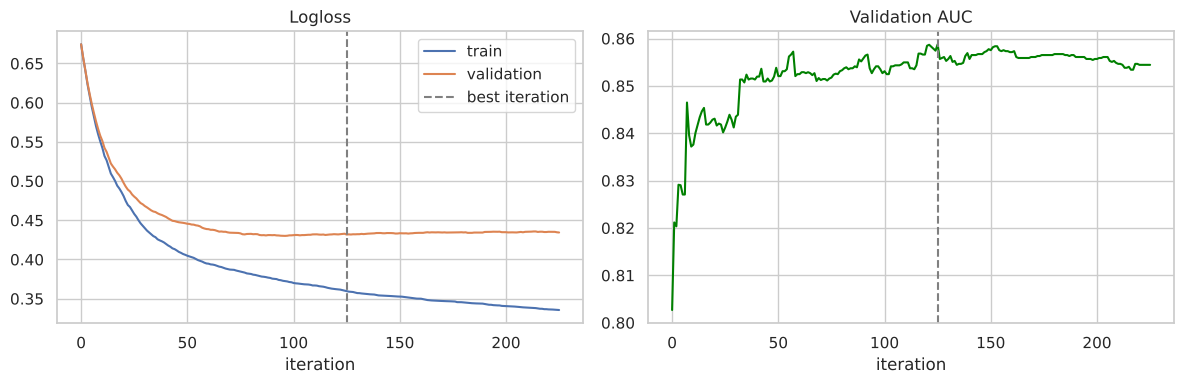

In [7]:
cb = CatBoostClassifier(iterations=1000, learning_rate=0.03, depth=4, loss_function="Logloss", eval_metric="AUC",
                        l2_leaf_reg=3, random_seed=SEED, early_stopping_rounds=100, verbose=100)
cb.fit(X_train, y_train, cat_features=CAT_COLS, eval_set=(X_val, y_val), use_best_model=True)
print("\nBest iteration:", cb.get_best_iteration(), "| trees kept:", cb.tree_count_)

ev = cb.get_evals_result()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ev["learn"]["Logloss"], label="train"); ax[0].plot(ev["validation"]["Logloss"], label="validation")
ax[0].axvline(cb.get_best_iteration(), color="gray", ls="--", label="best iteration"); ax[0].set_title("Logloss"); ax[0].set_xlabel("iteration"); ax[0].legend()
ax[1].plot(ev["validation"]["AUC"], color="green"); ax[1].axvline(cb.get_best_iteration(), color="gray", ls="--"); ax[1].set_title("Validation AUC"); ax[1].set_xlabel("iteration")
plt.tight_layout(); plt.show()

#### Cell 8 · Evaluate on the held-out test set
**What it does:** defines `evaluate()` (0.5 threshold), prints metrics and the classification report, and plots the confusion matrix and ROC curve.

* **Accuracy** $=\frac{TP+TN}{N}$ — share of correct predictions.
* **Precision** $=\frac{TP}{TP+FP}$ — of predicted survivors, how many truly survived.
* **Recall** $=\frac{TP}{TP+FN}$ — of real survivors, how many we found.
* **F1** — harmonic mean of precision and recall.
* **ROC-AUC** — chance a random survivor scores higher than a random non-survivor (threshold-free).

**What to say:** "Recall is lower than precision: at a 0.5 threshold the model is cautious about predicting survival."

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
CatBoost (default),0.7933,0.7857,0.6377,0.704,0.8385


              precision    recall  f1-score   support

        Died       0.80      0.89      0.84       110
    Survived       0.79      0.64      0.70        69

    accuracy                           0.79       179
   macro avg       0.79      0.76      0.77       179
weighted avg       0.79      0.79      0.79       179

Confusion matrix counts -> TN=98  FP=12  FN=25  TP=44


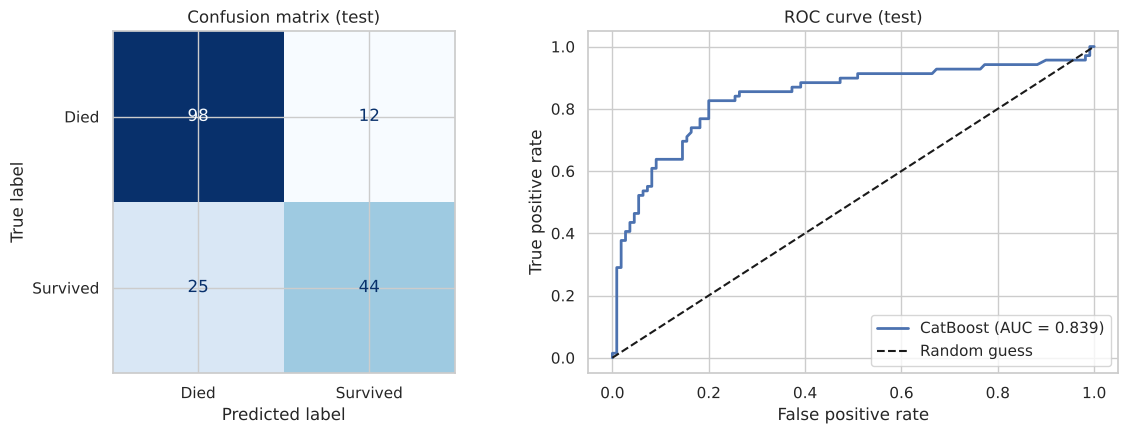

In [8]:
def evaluate(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"Model": name, "Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, proba)}

cb_proba = cb.predict_proba(X_test)[:, 1]
cb_pred = (cb_proba >= 0.5).astype(int)
cb_metrics = evaluate("CatBoost (default)", y_test, cb_proba)
display(pd.DataFrame([cb_metrics]).round(4).set_index("Model"))
print(classification_report(y_test, cb_pred, target_names=["Died", "Survived"]))
tn, fp, fn, tp = confusion_matrix(y_test, cb_pred).ravel()
print(f"Confusion matrix counts -> TN={tn}  FP={fp}  FN={fn}  TP={tp}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, cb_pred), display_labels=["Died", "Survived"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(y_test, cb_proba)
ax[1].plot(fpr, tpr, lw=2, label=f"CatBoost (AUC = {roc_auc_score(y_test, cb_proba):.3f})"); ax[1].plot([0, 1], [0, 1], "k--", label="Random guess")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].set_title("ROC curve (test)"); ax[1].legend()
plt.tight_layout(); plt.show()

#### Interpreting the evaluation results
**Confusion matrix (default CatBoost, 179 test passengers):** 98 correctly predicted deaths (TN), 44 correctly predicted survivors (TP), 12 passengers wrongly predicted to survive (FP) and 25 survivors the model missed (FN).

* **Accuracy 0.793** means about 4 in 5 predictions are right. Always predicting "died" would already score 110/179 = 61.5%, so the model adds real value beyond the majority-class baseline.
* **Precision 0.786:** when the model says "survived", it is right about 79% of the time (44 of 56).
* **Recall 0.638:** it finds only about 64% of real survivors (44 of 69). The model is better at recognising who died (89% of deaths correct) than who survived, because at a 0.5 threshold it is cautious about predicting survival.
* **F1 0.704** balances the two and is held back by the lower recall.
* **ROC-AUC 0.839:** a randomly chosen survivor gets a higher survival score than a randomly chosen non-survivor about 84% of the time, so the model ranks passengers well regardless of the threshold.
* **Practical meaning:** if missing a survivor were costlier than a false alarm, we would lower the threshold to trade some precision for higher recall (the Streamlit app has a slider for this).

#### Cell 9 · Interpretability: feature importance and SHAP
**What it does:** CatBoost's built-in importance (`PredictionValuesChange`), then exact SHAP values (`type="ShapValues"`; last column is the base value): mean |SHAP| per feature and a beeswarm plot.

**What to say:** "Sex, Title and Pclass dominate — the model rediscovers the evacuation policy. This is predictive association, **not causation**. In the beeswarm, categorical columns are shown as category codes only for colouring; positions are meaningful, colours for those columns are not."

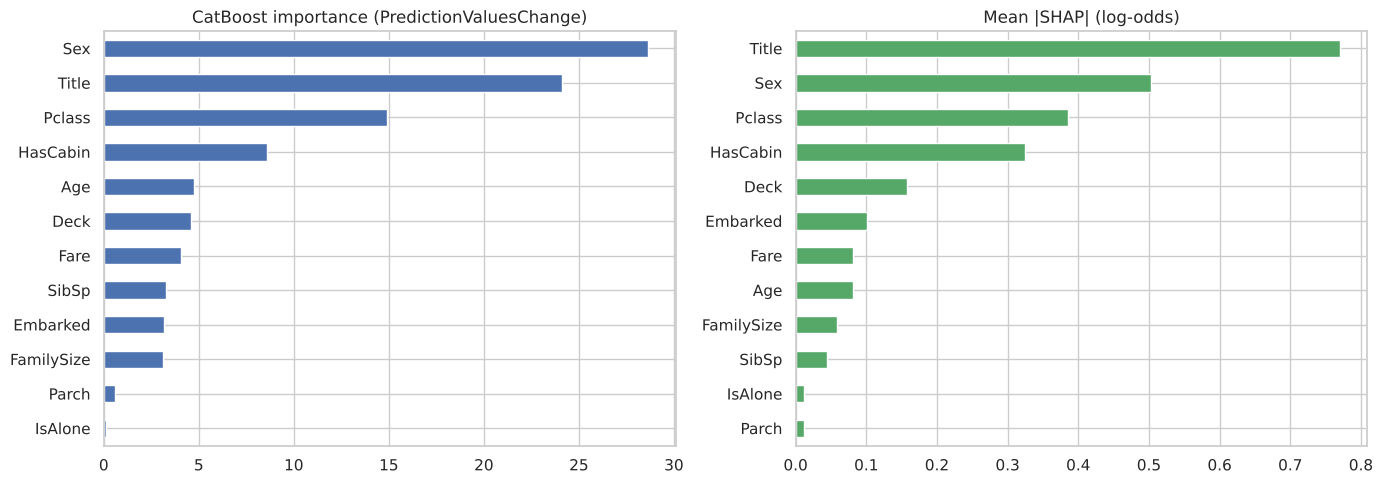

,importance
Sex,28.65
Title,24.14
Pclass,14.91
HasCabin,8.61
Age,4.76
Deck,4.57
Fare,4.08
SibSp,3.29
Embarked,3.17
FamilySize,3.10


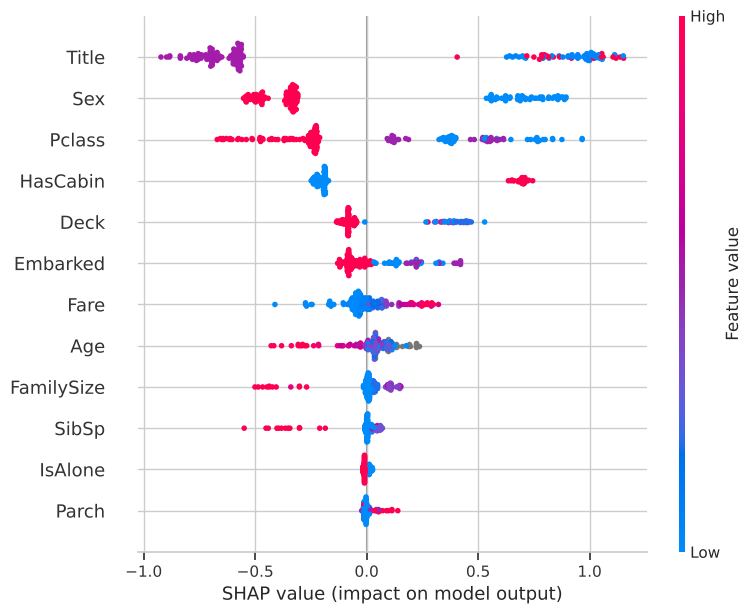

In [9]:
test_pool = Pool(X_test, y_test, cat_features=CAT_COLS)
imp = pd.Series(cb.get_feature_importance(test_pool), index=X_test.columns).sort_values()
shap_vals = cb.get_feature_importance(test_pool, type="ShapValues")
sv = shap_vals[:, :-1]                       # last column is the base value
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=X_test.columns).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp.plot.barh(ax=ax[0], color="#4c72b0"); ax[0].set_title("CatBoost importance (PredictionValuesChange)")
mean_abs.plot.barh(ax=ax[1], color="#55a868"); ax[1].set_title("Mean |SHAP| (log-odds)")
plt.tight_layout(); plt.show()
display(imp.sort_values(ascending=False).round(2).to_frame("importance"))

import shap
X_codes = X_test.copy()
for c in CAT_COLS: X_codes[c] = X_codes[c].astype("category").cat.codes
shap.summary_plot(sv, X_codes)

#### Cell 10 · Hyperparameter tuning with Optuna (+ early stopping)
**What it does:** `cv_scores` runs stratified 5-fold CV on train+validation only. Optuna's TPE sampler (seeded) searches 25 trials, maximising CV ROC-AUC; the best parameters are retrained with early stopping on the validation set and compared with the default model on the test set.

**Why these parameters and ranges**

| Parameter | Range searched | Why it was chosen |
|---|---|---|
| `depth` | 3 – 8 | Controls tree complexity ($2^{depth}$ leaves). With only ~700 training rows, deep trees overfit, so the range stays shallow |
| `learning_rate` | 0.01 – 0.2 (log scale) | Step size per tree. Small values are safer but need more trees; the search uses a fixed 300 trees, so the learning rate must balance speed and accuracy. Log scale because useful values differ by orders of magnitude |
| `l2_leaf_reg` | 1 – 30 (log scale) | L2 penalty on leaf values: stronger regularisation reduces overfitting on small, noisy data |
| `iterations` | fixed 300 in the search; up to 1500 with early stopping in the final fit | Early stopping picks the useful number of trees, so we do not need to search it |

**Why Optuna:** unlike GridSearchCV (tries every combination of a fixed grid) or RandomizedSearchCV (samples blindly), Optuna's TPE sampler learns from earlier trials where good values are, so 25 trials cover a continuous space efficiently. It plays the same role as those tools. **Metric:** ROC-AUC is threshold-independent and robust to the moderate class imbalance. The test set is never used for tuning.

**How to read the result:** the best parameters and tuned CV score are printed above the history plot. A higher CV score does not guarantee a better test score: with 179 test passengers, differences of a point or two are within noise.

Best CatBoost params: {'depth': 5, 'learning_rate': 0.1725, 'l2_leaf_reg': 12.0571} | CV ROC-AUC: 0.8913


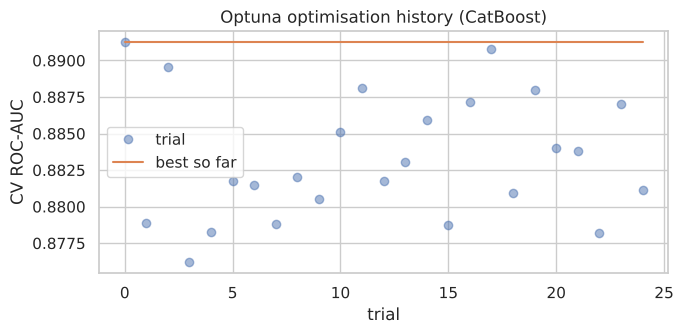

Tuned model best iteration: 75


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
CatBoost (default),0.7933,0.7857,0.6377,0.7040,0.8385
CatBoost (tuned),0.7821,0.7143,0.7246,0.7194,0.8358


In [10]:
N_TRIALS = 25
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_scores(make_model, X_, y_, cv, scoring=("roc_auc",)):
    # Manual CV loop: fresh model per fold, works with any estimator (incl. CatBoost with cat_features)
    out = {m: [] for m in scoring}
    for tr, va in cv.split(X_, y_):
        m = make_model(); m.fit(X_.iloc[tr], y_.iloc[tr])
        p = m.predict_proba(X_.iloc[va])[:, 1]
        if "roc_auc" in scoring: out["roc_auc"].append(roc_auc_score(y_.iloc[va], p))
        if "accuracy" in scoring: out["accuracy"].append(accuracy_score(y_.iloc[va], (p >= 0.5).astype(int)))
    return {k: np.array(v) for k, v in out.items()}

def objective_cb(trial):
    params = {"depth": trial.suggest_int("depth", 3, 8),
              "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
              "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 30, log=True)}
    make = lambda: CatBoostClassifier(iterations=300, random_seed=SEED, verbose=0, cat_features=CAT_COLS, **params)
    return cv_scores(make, X_trainval, y_trainval, skf)["roc_auc"].mean()

study_cb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_cb.optimize(objective_cb, n_trials=N_TRIALS)
best_params = study_cb.best_params
print("Best CatBoost params:", {k: round(v, 4) if isinstance(v, float) else v for k, v in best_params.items()},
      "| CV ROC-AUC:", round(study_cb.best_value, 4))

vals = [t.value for t in study_cb.trials]
plt.figure(figsize=(7, 3.5)); plt.plot(vals, "o", alpha=.5, label="trial"); plt.plot(np.maximum.accumulate(vals), label="best so far")
plt.xlabel("trial"); plt.ylabel("CV ROC-AUC"); plt.title("Optuna optimisation history (CatBoost)"); plt.legend(); plt.tight_layout(); plt.show()

# Final tuned model: best params + early stopping on the validation split
cb_tuned = CatBoostClassifier(iterations=1500, loss_function="Logloss", eval_metric="AUC", random_seed=SEED,
                              early_stopping_rounds=100, verbose=0, **best_params)
cb_tuned.fit(X_train, y_train, cat_features=CAT_COLS, eval_set=(X_val, y_val), use_best_model=True)
print("Tuned model best iteration:", cb_tuned.get_best_iteration())
cb_tuned_proba = cb_tuned.predict_proba(X_test)[:, 1]
cb_tuned_metrics = evaluate("CatBoost (tuned)", y_test, cb_tuned_proba)
display(pd.DataFrame([cb_metrics, cb_tuned_metrics]).round(4).set_index("Model"))

#### Cell 11 · Random Forest baseline (also tuned with Optuna) and comparison
**What it does:** Random Forest can't take strings or NaN, so a pipeline one-hot-encodes categoricals and median-imputes numerics — fit on training folds only. It gets the **same Optuna budget** (25 trials, same folds). Then a test-set comparison table, bar chart and ROC curves.

**What to say:** "Same split, same features, same CV folds, same tuning effort: that's what makes it fair. A 179-row test set is noisy, so don't over-read small gaps."

Best RF params: {'max_depth': 7, 'min_samples_leaf': 1, 'max_features': 0.742} | CV ROC-AUC: 0.8849


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
CatBoost (default),0.7933,0.7857,0.6377,0.7040,0.8385
CatBoost (tuned),0.7821,0.7143,0.7246,0.7194,0.8358
Random Forest (tuned),0.8045,0.8036,0.6522,0.7200,0.8449


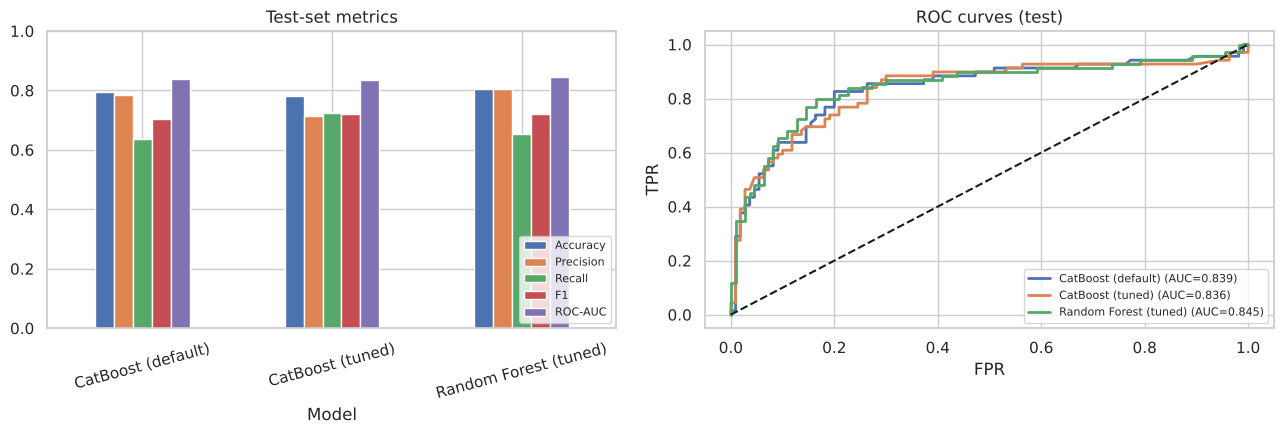

In [11]:
def make_preprocessor(kind="onehot"):
    if kind == "onehot":
        return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
                                  ("num", SimpleImputer(strategy="median", add_indicator=True), NUM_COLS)])
    return ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS),
                              ("num", "passthrough", NUM_COLS)])   # XGBoost / LightGBM handle NaN natively

def make_rf(**kw):
    return Pipeline([("prep", make_preprocessor("onehot")),
                     ("rf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, **kw))])

def objective_rf(trial):
    kw = {"max_depth": trial.suggest_int("max_depth", 3, 12), "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
          "max_features": trial.suggest_float("max_features", 0.2, 1.0)}
    return cv_scores(lambda: make_rf(**kw), X_trainval, y_trainval, skf)["roc_auc"].mean()

study_rf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_rf.optimize(objective_rf, n_trials=N_TRIALS)
print("Best RF params:", {k: round(v, 3) if isinstance(v, float) else v for k, v in study_rf.best_params.items()},
      "| CV ROC-AUC:", round(study_rf.best_value, 4))

rf_best = make_rf(**study_rf.best_params).fit(X_trainval, y_trainval)
rf_proba = rf_best.predict_proba(X_test)[:, 1]
comparison = pd.DataFrame([cb_metrics, cb_tuned_metrics, evaluate("Random Forest (tuned)", y_test, rf_proba)]).set_index("Model").round(4)
display(comparison)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
comparison.plot.bar(ax=ax[0], rot=15, ylim=(0, 1)); ax[0].set_title("Test-set metrics"); ax[0].legend(loc="lower right", fontsize=8)
for name, p in [("CatBoost (default)", cb_proba), ("CatBoost (tuned)", cb_tuned_proba), ("Random Forest (tuned)", rf_proba)]:
    f, t, _ = roc_curve(y_test, p); ax[1].plot(f, t, lw=2, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC curves (test)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Cell 12 · Repeated cross-validation: CatBoost vs Random Forest vs XGBoost vs LightGBM
**What it does:** 5-fold CV repeated 3 times (15 scores per model) with fixed, untuned, comparable settings — so no model gets a tuning advantage — then mean ± std.

**What to say:** "Differences are smaller than the standard deviations: the models are effectively tied. The practical difference is effort — CatBoost took raw categories and missing ages with no encoding."

,CV ROC-AUC,± AUC,CV Accuracy,± Acc
Model,,,,
CatBoost,0.8760,0.0311,0.8240,0.0224
Random Forest,0.8762,0.0258,0.8254,0.0234
XGBoost,0.8724,0.0291,0.8249,0.0243
LightGBM,0.8676,0.0285,0.8146,0.0293


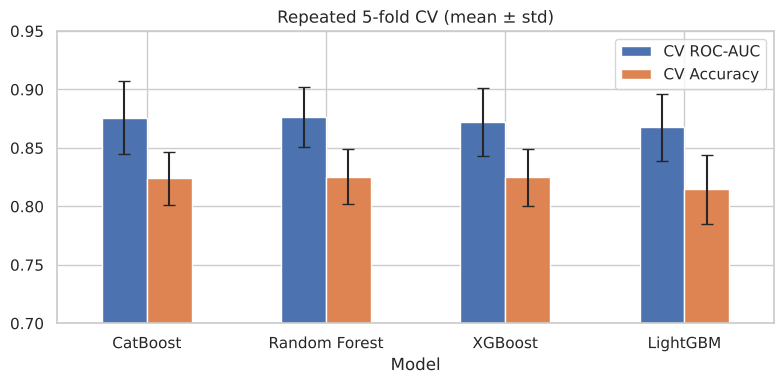

In [12]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
factories = {
    "CatBoost": lambda: CatBoostClassifier(iterations=300, learning_rate=0.05, depth=4, random_seed=SEED, verbose=0, cat_features=CAT_COLS),
    "Random Forest": lambda: make_rf(max_depth=6, min_samples_leaf=2),
    "XGBoost": lambda: Pipeline([("prep", make_preprocessor("ordinal")),
                                 ("m", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED, eval_metric="logloss"))]),
    "LightGBM": lambda: Pipeline([("prep", make_preprocessor("ordinal")),
                                  ("m", LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1))]),
}
rows = []
for name, mk in factories.items():
    sc = cv_scores(mk, X_trainval, y_trainval, rskf, scoring=("roc_auc", "accuracy"))
    rows.append({"Model": name, "CV ROC-AUC": sc["roc_auc"].mean(), "± AUC": sc["roc_auc"].std(),
                 "CV Accuracy": sc["accuracy"].mean(), "± Acc": sc["accuracy"].std()})
cv_table = pd.DataFrame(rows).set_index("Model").round(4)
display(cv_table)
cv_table[["CV ROC-AUC", "CV Accuracy"]].plot.bar(yerr=cv_table[["± AUC", "± Acc"]].values.T, rot=0, figsize=(8, 4), capsize=4, ylim=(0.7, 0.95))
plt.title("Repeated 5-fold CV (mean ± std)"); plt.tight_layout(); plt.show()

#### Cell 13 · Example passengers and Kaggle submission
**What it does:** five hypothetical passengers go through `add_features` and the tuned model (probability + class). Then the tuned model is retrained on **all** labeled data (early-stopped tree count) and writes `submission.csv` for `test.csv`; the format is checked against `gender_submission.csv` if present.

**What to say:** "These passengers are invented — the output shows patterns learned from 1912 data. `test.csv` has no labels, so no metrics are possible there; Kaggle would score the file."

In [13]:
examples = pd.DataFrame([
    {"Name": "Doe, Mrs. Jane", "Pclass": 1, "Sex": "female", "Age": 30, "SibSp": 1, "Parch": 0, "Fare": 90.0, "Cabin": "C85", "Embarked": "C"},
    {"Name": "Smith, Mr. John", "Pclass": 3, "Sex": "male", "Age": 28, "SibSp": 0, "Parch": 0, "Fare": 7.9, "Cabin": None, "Embarked": "S"},
    {"Name": "Brown, Master. Tom", "Pclass": 2, "Sex": "male", "Age": 6, "SibSp": 1, "Parch": 1, "Fare": 26.0, "Cabin": None, "Embarked": "S"},
    {"Name": "Lee, Miss. Anna", "Pclass": 3, "Sex": "female", "Age": 22, "SibSp": 0, "Parch": 0, "Fare": 8.1, "Cabin": None, "Embarked": "Q"},
    {"Name": "Grey, Mr. Henry", "Pclass": 1, "Sex": "male", "Age": 55, "SibSp": 0, "Parch": 0, "Fare": 60.0, "Cabin": "B30", "Embarked": "S"},
])
ex_proba = cb_tuned.predict_proba(add_features(examples)[FEATURES])[:, 1]
out = examples[["Name", "Pclass", "Sex", "Age", "Fare", "Embarked"]].copy()
out["P(survive)"] = ex_proba.round(3)
out["Prediction"] = np.where(ex_proba >= 0.5, "Survived (1)", "Died (0)")
display(out)

# Final model on all labeled data, then predict test.csv
final_model = CatBoostClassifier(loss_function="Logloss", random_seed=SEED, verbose=0,
                                 iterations=cb_tuned.get_best_iteration() + 1, **best_params)
final_model.fit(X, y, cat_features=CAT_COLS)
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"],
                           "Survived": final_model.predict(add_features(test_df)[FEATURES]).astype(int).ravel()})
submission.to_csv("submission.csv", index=False)
if os.path.exists("gender_submission.csv"):
    fmt = pd.read_csv("gender_submission.csv")
    print("Format matches gender_submission.csv:", list(fmt.columns) == list(submission.columns) and len(fmt) == len(submission))
print("Predicted survival rate on test.csv:", round(submission["Survived"].mean(), 3))
submission.head()

,Name,Pclass,Sex,Age,Fare,Embarked,P(survive),Prediction
0,"Doe, Mrs. Jane",1,female,30,90.0,C,0.984,Survived (1)
1,"Smith, Mr. John",3,male,28,7.9,S,0.119,Died (0)
2,"Brown, Master. Tom",2,male,6,26.0,S,0.834,Survived (1)
3,"Lee, Miss. Anna",3,female,22,8.1,Q,0.692,Survived (1)
4,"Grey, Mr. Henry",1,male,55,60.0,S,0.312,Died (0)


Format matches gender_submission.csv: True
Predicted survival rate on test.csv: 0.4


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


## Conclusions
**What we learned**
* How CatBoost works (ordered boosting, ordered target statistics, symmetric trees) and how to apply `CatBoostClassifier` with native categorical features and missing values.
* **Key drivers:** `Sex`, `Title`, `Pclass` (then `HasCabin`) — consistent with the EDA and the 'women and children first' policy. These are predictive associations, **not causal effects**.
* **Model comparison:** On the single 179-row test split, default CatBoost (accuracy 0.793, AUC 0.839), tuned CatBoost (0.782, 0.836) and tuned Random Forest (0.804, 0.845) are within a couple of passengers of each other. In repeated 5-fold CV, CatBoost (ROC-AUC 0.876) and Random Forest (0.876) tie, with XGBoost at 0.872 and LightGBM at 0.868, all inside one standard deviation (about 0.03). Optuna found a better CV score (0.891) but the tuned model did not beat the default on the test split — common on small data, where differences are within noise. No model is a decisive winner. (Numbers from the executed run; they may shift slightly with library versions.)
* Good evaluation needs more than accuracy (precision, recall, F1, ROC-AUC) and a fair protocol: same split, same folds, comparable tuning, and a test set used once.

**Model strengths**
* Strong results on tabular data with little preprocessing: raw categories and missing ages work as they are.
* Good defaults, built-in early stopping, overfitting control (ordered boosting, symmetric trees, L2 regularisation) and fast exact SHAP explanations.
* Optuna tuning needs only a few lines of code.

**Model weaknesses**
* Hyperparameter tuning gave no real test gain here, so on small data the defaults are already near the best.
* Recall is lower than precision at a 0.5 threshold: the model misses a share of real survivors.
* Slower to train than simpler models, and less transparent than a single decision tree or logistic regression.
* Small historical dataset (891 labeled passengers, 1912): not representative of other populations. `Fare`/`Cabin`/`Title` encode socio-economic status, so real-world use would raise fairness concerns.

**Possible improvements**
* Richer features (ticket / family-group survival computed **inside CV folds**, age imputation by title).
* Larger Optuna budgets, probability calibration and threshold tuning for a chosen precision/recall trade-off, ensembling.
* More data and repeated CV with confidence intervals for model selection.

**Best practices followed:** split before learning anything · stratified, seeded splits · validation set for early stopping, test set once · tune with CV · metrics chosen for the problem · preprocessing inside pipelines · no target-derived features computed on all data.

**References:** Prokhorenkova et al., *CatBoost: unbiased boosting with categorical features*, NeurIPS 2018 (https://arxiv.org/abs/1706.09516) · https://catboost.ai/en/docs/ · https://github.com/catboost/catboost · https://optuna.org · https://www.kaggle.com/competitions/titanic